## Lab: Market Return Dynamics

## Victor Zhang

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

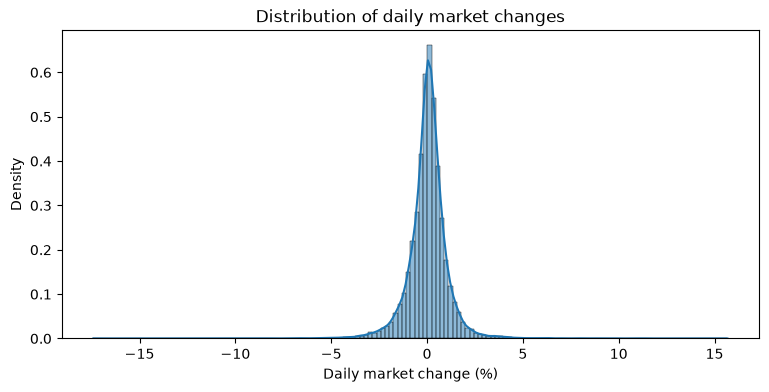

In [51]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

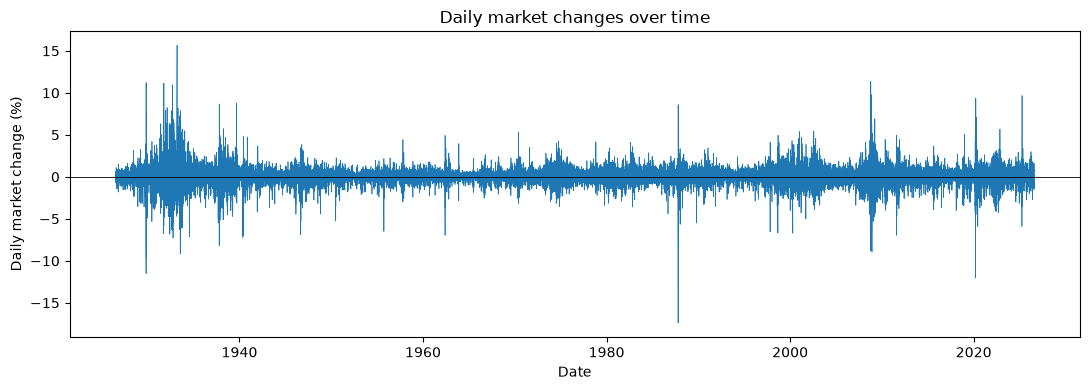

In [52]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [53]:
df_new = df[['date', 'year', 'month', 'month_start', 'trading_day_of_month', 'market_return_pct']]
df_new.head()

,date,year,month,month_start,trading_day_of_month,market_return_pct
0,1926-07-01,1926,7,1926-07-01,1,0.10
1,1926-07-02,1926,7,1926-07-01,2,0.46
2,1926-07-06,1926,7,1926-07-01,3,0.18
3,1926-07-07,1926,7,1926-07-01,4,0.10
4,1926-07-08,1926,7,1926-07-01,5,0.23


In [54]:
df_new['direction'] = df_new['market_return_pct'] > 0
df_new.head()

,date,year,month,month_start,trading_day_of_month,market_return_pct,direction
0,1926-07-01,1926,7,1926-07-01,1,0.10,True
1,1926-07-02,1926,7,1926-07-01,2,0.46,True
2,1926-07-06,1926,7,1926-07-01,3,0.18,True
3,1926-07-07,1926,7,1926-07-01,4,0.10,True
4,1926-07-08,1926,7,1926-07-01,5,0.23,True


In [55]:
df_new['direction'].dtype

dtype('bool')

In [56]:
df_new['direction'] = df_new['direction'].map({True: 'Up', False: 'Down'})
df_new.head()

,date,year,month,month_start,trading_day_of_month,market_return_pct,direction
0,1926-07-01,1926,7,1926-07-01,1,0.10,Up
1,1926-07-02,1926,7,1926-07-01,2,0.46,Up
2,1926-07-06,1926,7,1926-07-01,3,0.18,Up
3,1926-07-07,1926,7,1926-07-01,4,0.10,Up
4,1926-07-08,1926,7,1926-07-01,5,0.23,Up


In [57]:
next_day_return = df_new['market_return_pct'][1:]
next_day_return = pd.concat([next_day_return, pd.Series([np.nan])], ignore_index=True)
df_new['next_day_market_return_pct'] = next_day_return
df_new

,date,year,month,month_start,trading_day_of_month,market_return_pct,direction,next_day_market_return_pct
0,1926-07-01,1926,7,1926-07-01,1,0.10,Up,0.46
1,1926-07-02,1926,7,1926-07-01,2,0.46,Up,0.18
2,1926-07-06,1926,7,1926-07-01,3,0.18,Up,0.10
3,1926-07-07,1926,7,1926-07-01,4,0.10,Up,0.23
4,1926-07-08,1926,7,1926-07-01,5,0.23,Up,-0.70
...,...,...,...,...,...,...,...,...
26291,2026-07-27,2026,7,2026-07-01,18,0.17,Up,0.29
26292,2026-07-28,2026,7,2026-07-01,19,0.29,Up,-1.50
26293,2026-07-29,2026,7,2026-07-01,20,-1.50,Down,1.61
26294,2026-07-30,2026,7,2026-07-01,21,1.61,Up,0.70


In [58]:
df_new['next_day_direction'] = df_new['next_day_market_return_pct'] > 0
df_new['next_day_direction'] = df_new['next_day_direction'].map({True: 'Up', False: 'Down'})
df_new.head()

,date,year,month,month_start,trading_day_of_month,market_return_pct,direction,next_day_market_return_pct,next_day_direction
0,1926-07-01,1926,7,1926-07-01,1,0.10,Up,0.46,Up
1,1926-07-02,1926,7,1926-07-01,2,0.46,Up,0.18,Up
2,1926-07-06,1926,7,1926-07-01,3,0.18,Up,0.10,Up
3,1926-07-07,1926,7,1926-07-01,4,0.10,Up,0.23,Up
4,1926-07-08,1926,7,1926-07-01,5,0.23,Up,-0.70,Down


### Marginal PMF:

In [59]:
df_new.groupby(by=['direction']).size() / len(df_new)

direction
Down    0.452845
Up      0.547155
dtype: float64

Up transitions are more  common than down transitions.

### Joint PMF:

In [60]:
df_new.groupby(by=['direction', 'next_day_direction']).size() / len(df_new)

direction  next_day_direction
Down       Down                  0.224711
           Up                    0.228134
Up         Down                  0.228172
           Up                    0.318984
dtype: float64

### Conditional PMF given direction = Up: 

In [70]:
df_new[(df_new['direction'] == 'Up')].groupby(by='next_day_direction').size() / len(df_new[(df_new['direction'] == 'Up')])

next_day_direction
Down    0.417014
Up      0.582986
dtype: float64

### Conditional PMF given direction = Down: 

In [71]:
df_new[(df_new['direction'] == 'Down')].groupby(by='next_day_direction').size() / len(df_new[(df_new['direction'] == 'Down')])

next_day_direction
Down    0.496221
Up      0.503779
dtype: float64

You are more likely to transition to an Up day from an Up day than from a Down day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [76]:
bin_edges = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
bin_labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df_new['return_category'] = pd.cut(df_new['market_return_pct'], 
    bins=bin_edges, labels=bin_labels, right=True, retbins=False)
df_new['next_day_return_category'] = pd.cut(df_new['next_day_market_return_pct'], 
    bins=bin_edges, labels=bin_labels, right=True, retbins=False)
df_new.head()


,date,year,month,month_start,trading_day_of_month,market_return_pct,direction,next_day_market_return_pct,next_day_direction,return_category,next_day_return_category
0,1926-07-01,1926,7,1926-07-01,1,0.10,Up,0.46,Up,Near zero,Small gain
1,1926-07-02,1926,7,1926-07-01,2,0.46,Up,0.18,Up,Small gain,Small gain
2,1926-07-06,1926,7,1926-07-01,3,0.18,Up,0.10,Up,Small gain,Near zero
3,1926-07-07,1926,7,1926-07-01,4,0.10,Up,0.23,Up,Near zero,Small gain
4,1926-07-08,1926,7,1926-07-01,5,0.23,Up,-0.70,Down,Small gain,Small loss


In [80]:
df_new.groupby(by=['return_category']).size()

return_category
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
dtype: int64

The most common category is small gain, which made up 9785 days. The second most common category is small loss, which made up 7452 days.

### Joint PMF:

In [79]:
df_new.groupby(by=['return_category', 'next_day_return_category']).size() / len(df_new)

return_category  next_day_return_category
Large loss       Large loss                  0.021334
                 Small loss                  0.027190
                 Near zero                   0.009051
                 Small gain                  0.027799
                 Large gain                  0.019547
Small loss       Large loss                  0.035443
                 Small loss                  0.088645
                 Near zero                   0.034150
                 Small gain                  0.097772
                 Large gain                  0.027381
Near zero        Large loss                  0.009317
                 Small loss                  0.041984
                 Near zero                   0.020954
                 Small gain                  0.049323
                 Large gain                  0.009279
Small gain       Large loss                  0.024985
                 Small loss                  0.100053
                 Near zero              

The most common transition is small gain to small gain at about 0.16 probability, and the second most common is small gain to small loss at about 0.10 probability.

### Marginal PMFs:

In [81]:
df_new.groupby(by=['return_category']).size() / len(df_new)

return_category
Large loss    0.104921
Small loss    0.283389
Near zero     0.130856
Small gain    0.372110
Large gain    0.108724
dtype: float64

In [78]:
df_new.groupby(by=['next_day_return_category']).size() / len(df_new)

next_day_return_category
Large loss    0.104921
Small loss    0.283389
Near zero     0.130818
Small gain    0.372110
Large gain    0.108724
dtype: float64

Conditional PMF given 'return_category' = 'Large loss': The most common next day category was small gain, followed by small loss. The expected percent return for the next day was -0.038. The minimum next day percent return was -17.410, and the maximum was 11.220.

In [83]:
df_new[df_new['return_category'] == 'Large loss'].groupby(
    by=['next_day_return_category']).size() / len(df_new[df_new['return_category'] == 'Large loss'])

next_day_return_category
Large loss    0.203335
Small loss    0.259152
Near zero     0.086263
Small gain    0.264951
Large gain    0.186299
dtype: float64

In [92]:
df_new[df_new['return_category'] == 'Large loss']['next_day_market_return_pct'].describe()

count    2759.000000
mean       -0.038311
std         1.720570
min       -17.410000
25%        -0.790000
50%        -0.010000
75%         0.720000
max        11.220000
Name: next_day_market_return_pct, dtype: float64

Conditional PMF given 'return_category' = 'Small loss': The most common next day category is small gain, followed by small loss. The expected percent return for the next day was -0.044. The minimum next day percent return was -11.230, and the maximum was 11.360.

In [84]:
df_new[df_new['return_category'] == 'Small loss'].groupby(
    by=['next_day_return_category']).size() / len(df_new[df_new['return_category'] == 'Small loss'])

next_day_return_category
Large loss    0.125067
Small loss    0.312802
Near zero     0.120505
Small gain    0.345008
Large gain    0.096618
dtype: float64

In [91]:
df_new[df_new['return_category'] == 'Small loss']['next_day_market_return_pct'].describe()

count    7452.000000
mean       -0.043814
std         1.009529
min       -11.230000
25%        -0.530000
50%         0.010000
75%         0.450000
max        11.360000
Name: next_day_market_return_pct, dtype: float64

Conditional PMF given 'return_category' = 'Near zero': The most common next day return category was small gain, followed by small loss. The expected percent return for the next day was 0.015. The minimum next day percent return was -8.190, and the maximum was 5.490.

In [85]:
df_new[df_new['return_category'] == 'Near zero'].groupby(
    by=['next_day_return_category']).size() / len(df_new[df_new['return_category'] == 'Near zero'])

next_day_return_category
Large loss    0.071200
Small loss    0.320837
Near zero     0.160128
Small gain    0.376925
Large gain    0.070910
dtype: float64

In [94]:
df_new[df_new['return_category'] == 'Near zero']['next_day_market_return_pct'].describe()

count    3441.000000
mean        0.015013
std         0.826054
min        -8.190000
25%        -0.350000
50%         0.030000
75%         0.420000
max         5.490000
Name: next_day_market_return_pct, dtype: float64

Conditional PMF given 'return_category' = 'Small gain': The most common next day return category was small gain, followed by small loss. The expected percent return for the next day was 0.107. The minimum next day percent return was -8.250, and the maximum was 15.670.

In [86]:
df_new[df_new['return_category'] == 'Small gain'].groupby(
    by=['next_day_return_category']).size() / len(df_new[df_new['return_category'] == 'Small gain'])

next_day_return_category
Large loss    0.067144
Small loss    0.268881
Near zero     0.147879
Small gain    0.428411
Large gain    0.087583
dtype: float64

In [95]:
df_new[df_new['return_category'] == 'Small gain']['next_day_market_return_pct'].describe()

count    9784.000000
mean        0.106810
std         0.832186
min        -8.250000
25%        -0.250000
50%         0.120000
75%         0.500000
max         8.670000
Name: next_day_market_return_pct, dtype: float64

Conditional PMF given 'return_category' = 'Large gain': The most common next day return category is small gain, followed by small loss. The expected percent return for the next day was 0.163. The minimum next day percent return was -12.000, and the maximum next day percent return was 15.670.

In [87]:
df_new[df_new['return_category'] == 'Large gain'].groupby(
    by=['next_day_return_category']).size() / len(df_new[df_new['return_category'] == 'Large gain'])

next_day_return_category
Large loss    0.127317
Small loss    0.234697
Near zero     0.107030
Small gain    0.347674
Large gain    0.183281
dtype: float64

In [96]:
df_new[df_new['return_category'] == 'Large gain']['next_day_market_return_pct'].describe()

count    2859.000000
mean        0.163092
std         1.384086
min       -12.000000
25%        -0.370000
50%         0.150000
75%         0.730000
max        15.670000
Name: next_day_market_return_pct, dtype: float64

For every return category, the most common next day return category was small gain, and the second most common next day category was samll loss. The conditional PMFs for each return category weren't very close to uniform distributions because the probabilities of the next day's return being small gain or small loss were larger by decent amounts than the probabilities of the other categories.

Large loss and small loss had expected next day return percentages of -0.038 and -0.044, both close to zero and negative. Near zero, small gain, and large gain had expected next day return percentages of 0.015, 0.107 and 0.163. All three are positive, but the expected next day return for near zero is also near zero, while the expected next day return for both small and large gains is a small gain.

Large losses and large gains, the two extreme categories, had the highest standard deviation of next day return percentage, at 1.720 and 1.384, respectively. 

The more extreme categories had lower minimum and higher maximum next day return percentages. The large loss, small loss, and near zero categories had minimums further away from zero than their maximums. The small gain and large gain categories had maximums farther from zero than their minimums.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 

In [97]:
df_new['y_t'] = pd.qcut(df_new['market_return_pct'], q=21)
df_new['y_tp1'] = df_new['y_t'].shift(-1)
df_new.head()

,date,year,month,month_start,trading_day_of_month,market_return_pct,direction,next_day_market_return_pct,next_day_direction,return_category,next_day_return_category,y_t,y_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.10,Up,0.46,Up,Near zero,Small gain,"(0.04, 0.11]","(0.44, 0.54]"
1,1926-07-02,1926,7,1926-07-01,2,0.46,Up,0.18,Up,Small gain,Small gain,"(0.44, 0.54]","(0.11, 0.18]"
2,1926-07-06,1926,7,1926-07-01,3,0.18,Up,0.10,Up,Small gain,Near zero,"(0.11, 0.18]","(0.04, 0.11]"
3,1926-07-07,1926,7,1926-07-01,4,0.10,Up,0.23,Up,Near zero,Small gain,"(0.04, 0.11]","(0.18, 0.26]"
4,1926-07-08,1926,7,1926-07-01,5,0.23,Up,-0.70,Down,Small gain,Small loss,"(0.18, 0.26]","(-0.78, -0.57]"


- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

In [104]:
joint_pmf = df_new.groupby(by=['y_t', 'y_tp1']).size() / df_new['y_tp1'].notna().sum()
joint_pmf

y_t               y_tp1           
(-17.411, -1.61]  (-17.411, -1.61]    0.006959
                  (-1.61, -1.07]      0.003651
                  (-1.07, -0.78]      0.002928
                  (-0.78, -0.57]      0.001787
                  (-0.57, -0.42]      0.002206
                                        ...   
(1.55, 15.67]     (0.54, 0.67]        0.001369
                  (0.67, 0.84]        0.002586
                  (0.84, 1.09]        0.002814
                  (1.09, 1.55]        0.002966
                  (1.55, 15.67]       0.006655
Length: 441, dtype: float64

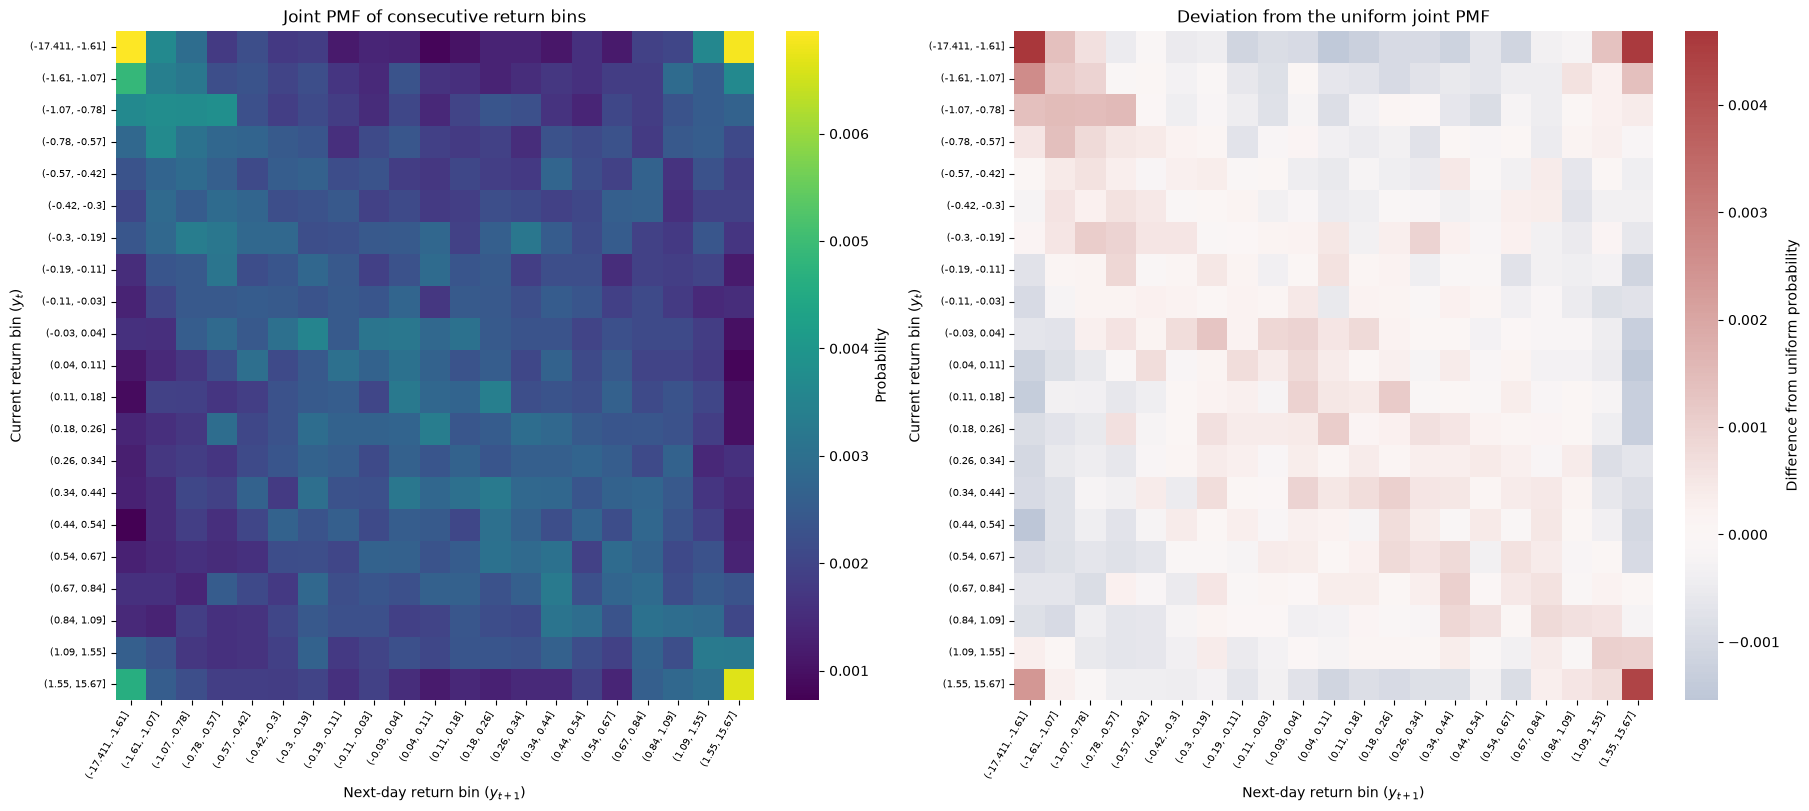

In [ ]:
# I used AI to help me with the coding for this cell
joint_pmf_matrix = joint_pmf.unstack('y_tp1')
uniform_joint_pmf = 1 / 21**2

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

sns.heatmap(
    joint_pmf_matrix,
    cmap='viridis',
    cbar_kws={'label': 'Probability'},
    ax=axes[0],
)
axes[0].set_title('Joint PMF of consecutive return bins')
axes[0].set_xlabel('Next-day return bin ($y_{t+1}$)')
axes[0].set_ylabel('Current return bin ($y_t$)')

sns.heatmap(
    joint_pmf_matrix - uniform_joint_pmf,
    cmap='vlag',
    center=0,
    cbar_kws={'label': 'Difference from uniform probability'},
    ax=axes[1],
)
axes[1].set_title('Deviation from the uniform joint PMF')
axes[1].set_xlabel('Next-day return bin ($y_{t+1}$)')
axes[1].set_ylabel('Current return bin ($y_t$)')

for ax in axes:
    ax.tick_params(axis='x', labelrotation=60, labelsize=7)
    ax.tick_params(axis='y', labelrotation=0, labelsize=7)
    plt.setp(ax.get_xticklabels(), ha='right')

plt.show()

I can see that very large gains and losses are more likely than the average day to be followed by very large gains or losses. Also, all of the tiles on and near the diagonal have higher probability than most of the other tiles. This means the next day return is a bit more likely than a uniform distribution to be part of the same bin as the current day return (or part of a nearby bin).

- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

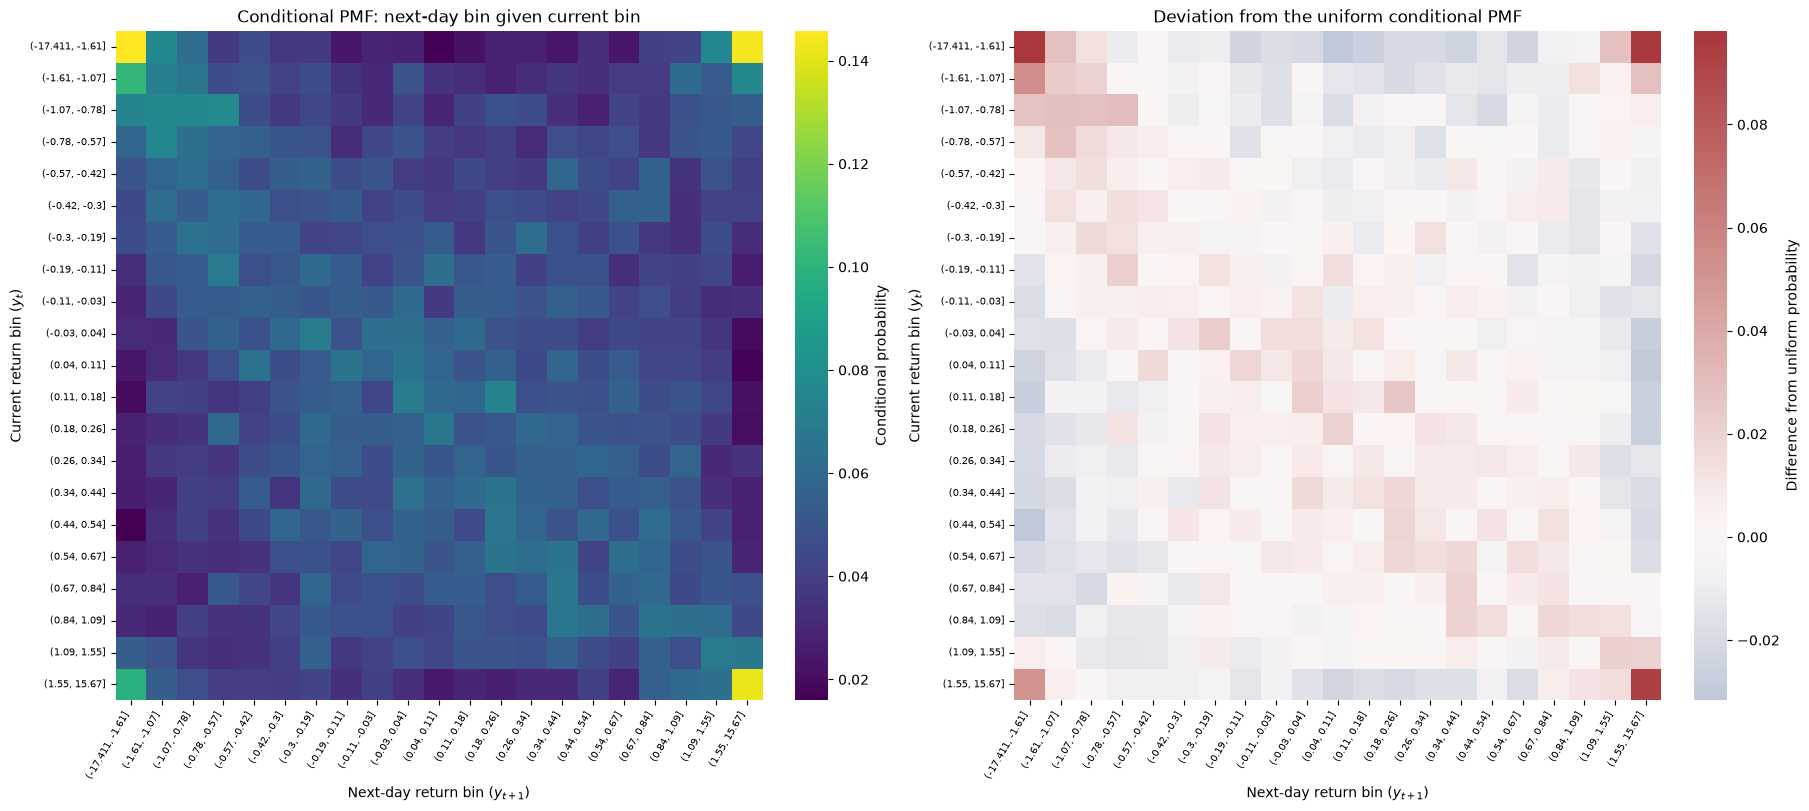

In [108]:
# I used AI to help me with the coding for this cell

# Normalize each row to get P(y_{t+1} | y_t)
conditional_pmf_matrix = joint_pmf_matrix.div(
    joint_pmf_matrix.sum(axis=1),
    axis=0,
)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

sns.heatmap(
    conditional_pmf_matrix,
    cmap="viridis",
    cbar_kws={"label": "Conditional probability"},
    ax=axes[0],
)
axes[0].set_title("Conditional PMF: next-day bin given current bin")
axes[0].set_xlabel("Next-day return bin ($y_{t+1}$)")
axes[0].set_ylabel("Current return bin ($y_t$)")

sns.heatmap(
    conditional_pmf_matrix - 1 / 21,
    cmap="vlag",
    center=0,
    cbar_kws={"label": "Difference from uniform probability"},
    ax=axes[1],
)
axes[1].set_title("Deviation from the uniform conditional PMF")
axes[1].set_xlabel("Next-day return bin ($y_{t+1}$)")
axes[1].set_ylabel("Current return bin ($y_t$)")

for ax in axes:
    ax.tick_params(axis="x", labelrotation=60, labelsize=7)
    ax.tick_params(axis="y", labelrotation=0, labelsize=7)
    plt.setp(ax.get_xticklabels(), ha="right")

plt.show()

I see almost the same patterns as the previous plot for the joint PMF. Very large gains and losses are more likely than the average day to be followed by very large gains or losses. The tiles on and near the diagonal have higher probability than most of the other tiles.

- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 

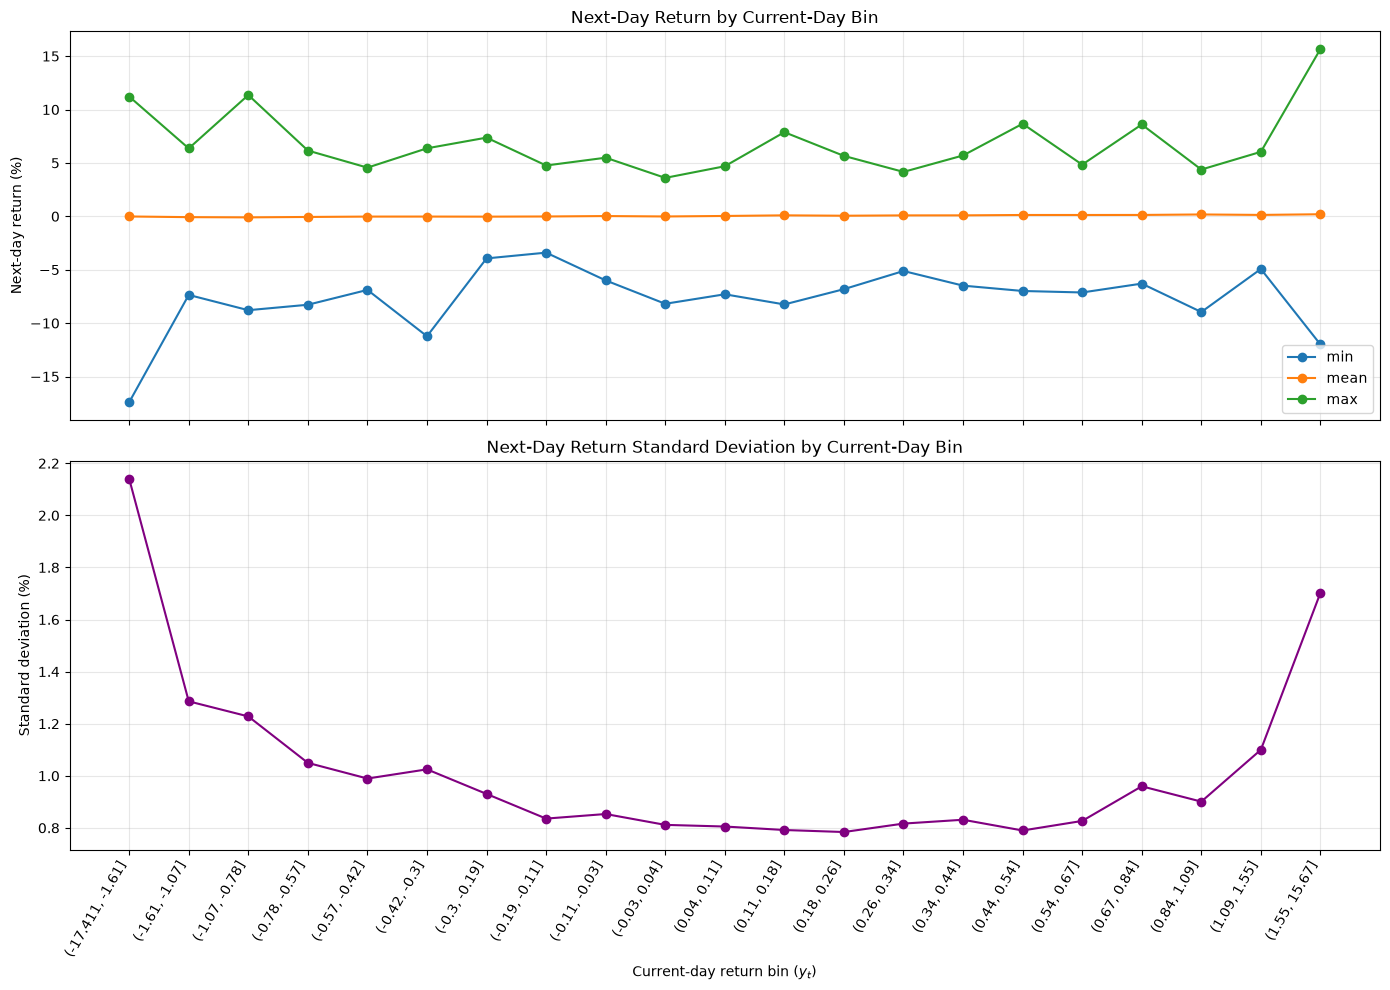

In [109]:
# I used AI to help me with the coding for this cell

# Summarize the next day's return for each current-day bin
next_day_stats = df_new.groupby('y_t', observed=False)[
    'next_day_market_return_pct'
].agg(['min', 'mean', 'max', 'std'])

# Use bin numbers for the x-axis, with the interval labels as ticks
x = range(len(next_day_stats))
bin_labels = [str(bin_interval) for bin_interval in next_day_stats.index]

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Next-day minimum, mean, and maximum
for statistic in ['min', 'mean', 'max']:
    axes[0].plot(x, next_day_stats[statistic], marker='o', label=statistic)

axes[0].set_title("Next-Day Return by Current-Day Bin")
axes[0].set_ylabel("Next-day return (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Next-day standard deviation
axes[1].plot(x, next_day_stats['std'], marker='o', color='purple')
axes[1].set_title("Next-Day Return Standard Deviation by Current-Day Bin")
axes[1].set_xlabel("Current-day return bin ($y_t$)")
axes[1].set_ylabel("Standard deviation (%)")
axes[1].grid(True, alpha=0.3)

axes[1].set_xticks(list(x))
axes[1].set_xticklabels(bin_labels, rotation=60, ha='right')

plt.tight_layout()
plt.show()

The first and last bins have higher maximums and lower minimums than almost all of the other bins. Every bin has mean next day returns of about zero. The standard deviation graph is in the shape of a bowl where the left side is higher than the right side. More extreme current-day returns, whether positive or negative, have higher standard deviations of next-day returns.

- How easy is it to predict the market?

It's difficult, not easy at all. It's very hard to predict tomorrow's return just by looking at today's return.